<style>
@media print {
  body { font-size: 10pt; line-height: 1.3; }
  pre, code { font-size: 8.5pt; white-space: pre-wrap; word-break: break-all; }
  .jp-Cell { page-break-inside: avoid; break-inside: avoid; margin-bottom: 10px; }
  img { max-width: 75% !important; height: auto; display: block; margin: 0 auto; }
}
</style>

# 1. Tree-Based Methods

## (a),(b) Download and Data Preparation and Data Missing Imputation

### i :  Research what types of techniques?
1. Statistical methods: Mean, median, mode, constant values, or random sampling. /// 2. Missing indicators: Binary columns identifying missing entries./// 3. Groupwise imputation: Statistics calculated within relevant subgroups./// 4. Predictive methods: KNN, regression, and iterative tree-based imputation./// 5. Time-series methods: Forward/backward fill, interpolation, and Kalman filtering./// 6. Deep learning: Autoencoders, VAEs, and GAN-based methods./// 7. Native handling: Models that directly accommodate missing values.

My Solution: MissForest//// I used MissForest to impute missing values in the Scania dataset. It iteratively fits Random Forest models to capture nonlinear relationships among variables without assuming normality.

In [1]:
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.metrics import classification_report, roc_auc_score
import os

# Hide the main tkinter window
root = tk.Tk()
root.withdraw()

# 1. Select and load datasets
print("Please select the 'aps_failure_training_set.csv' file...")
train_file_path = filedialog.askopenfilename(
    title="Select Training Dataset",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

print("Please select the 'aps_failure_test_set.csv' file...")
test_file_path = filedialog.askopenfilename(
    title="Select Test Dataset",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if train_file_path and test_file_path:
    print(f"\nTraining file path: {train_file_path}")
    print(f"Test file path: {test_file_path}")
    
    # Load datasets (skipping 20 lines of documentation and handling 'na' values)
    train_df = pd.read_csv(train_file_path, skiprows=20, na_values=['na'])
    test_df = pd.read_csv(test_file_path, skiprows=20, na_values=['na'])
    
    print("Training dataset shape:", train_df.shape)
    print("Test dataset shape:", test_df.shape)

    # Separate features and target variable for training set
    X_train = train_df.drop(columns=['class'])
    y_train = train_df['class'].map({'neg': 0, 'pos': 1})

    # Separate features and target variable for test set
    X_test = test_df.drop(columns=['class'])
    y_test = test_df['class'].map({'neg': 0, 'pos': 1})

    # 2. Configure IterativeImputer (MissForest approach) with optimized settings for speed
    imputer = IterativeImputer(
        estimator=ExtraTreesRegressor(n_estimators=5, random_state=42, n_jobs=-1),
        max_iter=2,          # Reduced iterations for fast execution
        sample_posterior=False,
        random_state=42,
        verbose=1
    )

    # 3. Subsampling for fast Imputer fitting
    print("\nTaking a random sample of 10,000 rows from training data to fit the imputer...")
    X_train_sample = X_train.sample(n=10000, random_state=42)
    
    # Fit the imputer on the sample and transform both train and test sets
    print("Fitting imputer on the training sample...")
    imputer.fit(X_train_sample)
    
    print("Transforming full training dataset...")
    X_train_imputed_array = imputer.transform(X_train)
    
    print("Transforming test dataset...")
    X_test_imputed_array = imputer.transform(X_test)

    # Convert NumPy arrays back to DataFrames with original column names
    X_train_imputed = pd.DataFrame(X_train_imputed_array, columns=X_train.columns)
    X_test_imputed = pd.DataFrame(X_test_imputed_array, columns=X_test.columns)

    # Save imputed datasets and targets to disk (in the current directory)
    print("\nSaving processed datasets to disk as pickle files...")
    X_train_imputed.to_pickle("X_train_imputed.pkl")
    X_test_imputed.to_pickle("X_test_imputed.pkl")
    y_train.to_pickle("y_train.pkl")
    y_test.to_pickle("y_test.pkl")
    print(f"Files saved successfully in: {os.getcwd()}")

    # 4. Configure and train the Random Forest Classifier
    classifier = RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced', 
        n_jobs=-1
    )

    print("\nTraining the Random Forest classifier on imputed data...")
    classifier.fit(X_train_imputed, y_train)
    print("Model training completed successfully.")

    # 5. Evaluate on Training Data
    y_train_pred = classifier.predict(X_train_imputed)
    y_train_proba = classifier.predict_proba(X_train_imputed)[:, 1]

    print("\n--- Training Set Evaluation Report ---")
    print(classification_report(y_train, y_train_pred, target_names=['Negative (0)', 'Positive (1)']))
    print("ROC-AUC Score (Train):", roc_auc_score(y_train, y_train_proba))

    # 6. Evaluate on Test Data
    y_test_pred = classifier.predict(X_test_imputed)
    y_test_proba = classifier.predict_proba(X_test_imputed)[:, 1]

    print("\n--- Test Set Evaluation Report ---")
    print(classification_report(y_test, y_test_pred, target_names=['Negative (0)', 'Positive (1)']))
    print("ROC-AUC Score (Test):", roc_auc_score(y_test, y_test_proba))

else:
    print("File selection was cancelled or incomplete.")

Please select the 'aps_failure_training_set.csv' file...
Please select the 'aps_failure_test_set.csv' file...

Training file path: C:/Users/Dr.yazdani/Desktop/My secret/Machine Learning for Data Science/PDF New Homework- 8 Sets/Homework 6 Data/aps_failure_training_set.csv
Test file path: C:/Users/Dr.yazdani/Desktop/My secret/Machine Learning for Data Science/PDF New Homework- 8 Sets/Homework 6 Data/aps_failure_test_set.csv
Training dataset shape: (60000, 171)
Test dataset shape: (16000, 171)

Taking a random sample of 10,000 rows from training data to fit the imputer...
Fitting imputer on the training sample...
[IterativeImputer] Completing matrix with shape (10000, 170)
[IterativeImputer] Change: 1957641798.0316448, scaled tolerance: 4272595.43 
[IterativeImputer] Change: 2591870109.6000004, scaled tolerance: 4272595.43 
Transforming full training dataset...


C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


[IterativeImputer] Completing matrix with shape (60000, 170)
Transforming test dataset...
[IterativeImputer] Completing matrix with shape (16000, 170)

Saving processed datasets to disk as pickle files...
Files saved successfully in: C:\Users\Dr.yazdani

Training the Random Forest classifier on imputed data...
Model training completed successfully.

--- Training Set Evaluation Report ---
              precision    recall  f1-score   support

Negative (0)       1.00      1.00      1.00     59000
Positive (1)       0.99      1.00      0.99      1000

    accuracy                           1.00     60000
   macro avg       0.99      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000

ROC-AUC Score (Train): 1.0

--- Test Set Evaluation Report ---
              precision    recall  f1-score   support

Negative (0)       0.99      1.00      1.00     15625
Positive (1)       0.84      0.74      0.79       375

    accuracy                           0.99     16000
 

In [2]:
import pandas as pd

# Reload processed data into memory
X_train_imputed = pd.read_pickle("X_train_imputed.pkl")
X_test_imputed = pd.read_pickle("X_test_imputed.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")

print("Data loaded successfully.")

Data loaded successfully.


##### ii :  calculate the coefficient of variation CV ?///##### iii :  Plot a correlation matrix for your features using pandas?/// ##### iv : Pick √170 features with highest CV?/// ##### v : Determine the number of positive and negative data?

Please select the 'aps_failure_training_set.csv' file...
Please select the 'aps_failure_test_set.csv' file...

=== (ii) Coefficient of Variation (CV) for Features ===
Top 10 Features with Highest Coefficient of Variation (CV):
             Mean (m)       Std (s)          CV
cs_009     779.197755  1.843585e+05  236.600371
cf_000  190221.810984  4.040441e+07  212.406837
co_000  190515.566938  4.040441e+07  212.079320
ad_000  190620.639314  4.040441e+07  211.962417
dh_000    4707.073332  5.602799e+05  119.029346
dj_000      39.938564  4.533142e+03  113.502884
ag_000     221.636367  2.047846e+04   92.396677
as_000     126.736521  1.101004e+04   86.873473
ay_009    1162.621618  9.796080e+04   84.258541
ak_000     979.489964  7.583162e+04   77.419496

Selected top 13 features with highest CV: ['cs_009', 'cf_000', 'co_000', 'ad_000', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'au_000', 'ch_000']

=== (iii) Feature Correlation Matrix (Top 13 Features) ===
Calculating

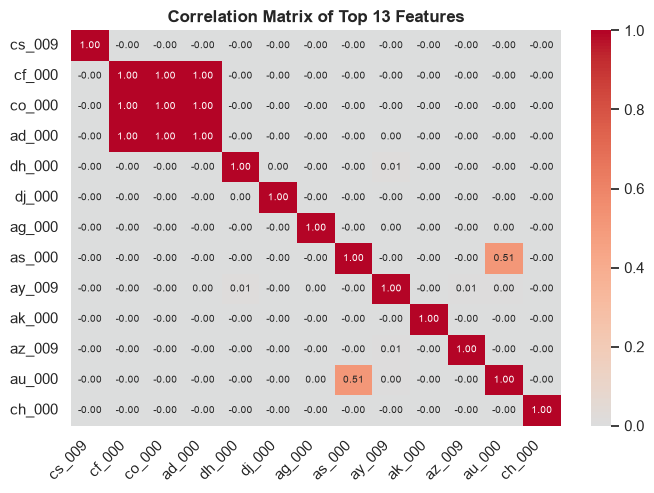

Correlation matrix plotted and saved as 'feature_correlation_matrix_top.png'.

=== (iv) Top sqrt(170) Features Visualization ===


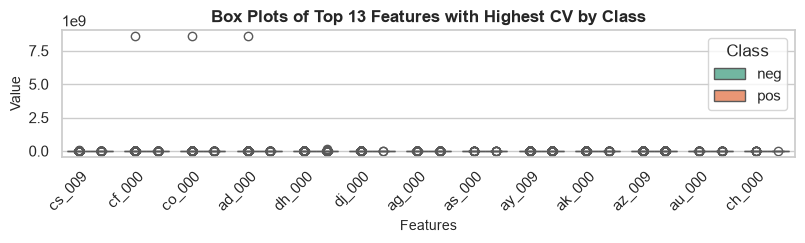

Box plots plotted and saved as 'top_features_boxplots.png'.
Plotting pairplot (scatter plots) for top 4 features...


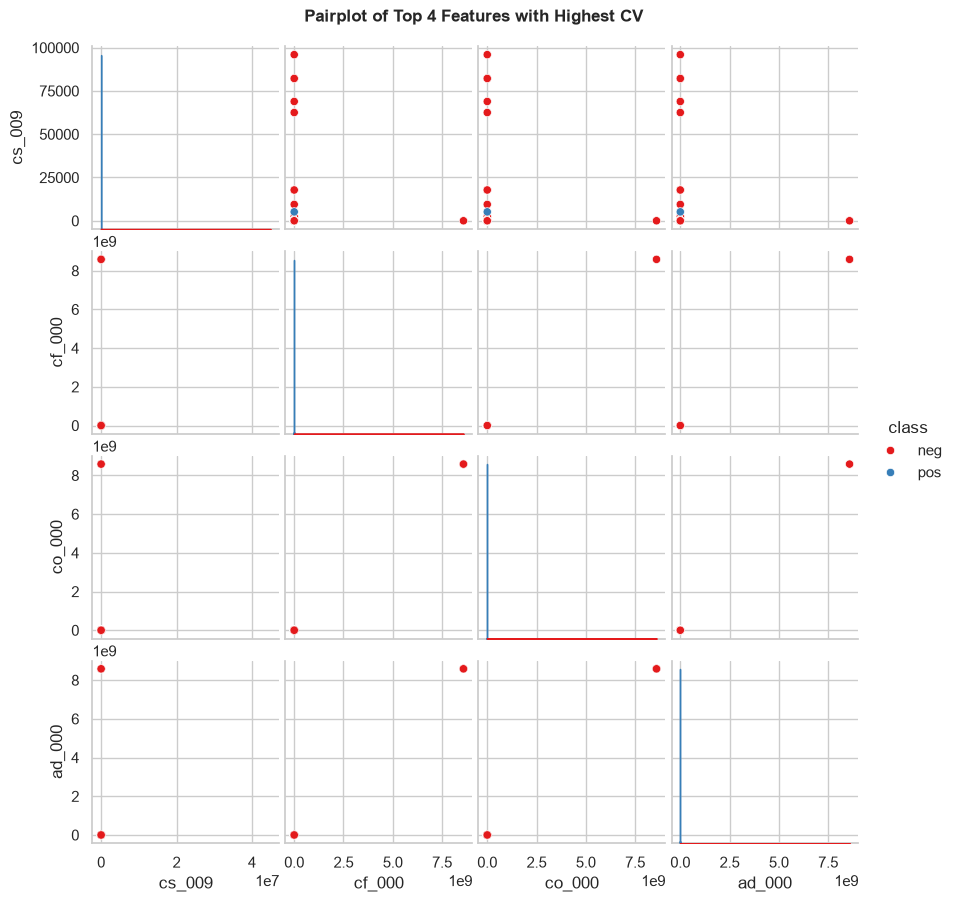

Pairplot plotted and saved as 'top_features_pairplot.png'.

=== (v) Class Distribution (Positive & Negative Counts) ===
Training Set:
  - Negative (neg): 59000
  - Positive (pos): 1000

Test Set:
  - Negative (neg): 15625
  - Positive (pos): 375


In [2]:
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for plots and compact rendering sizes for Jupyter Notebook
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})

# Hide the main tkinter window
root = tk.Tk()
root.withdraw()

# 1. Select and load training and test datasets via file dialog
print("Please select the 'aps_failure_training_set.csv' file...")
train_file_path = filedialog.askopenfilename(
    title="Select Training Dataset",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

print("Please select the 'aps_failure_test_set.csv' file...")
test_file_path = filedialog.askopenfilename(
    title="Select Test Dataset",
    filetypes=[("CSV Files", "*.csv"), ("All Files", "*.*")]
)

if train_file_path and test_file_path:
    # Load datasets (skipping 20 lines of documentation and handling 'na' values)
    train_df = pd.read_csv(train_file_path, skiprows=20, na_values=['na'])
    test_df = pd.read_csv(test_file_path, skiprows=20, na_values=['na'])
    
    # Separate features from target variable
    X_train = train_df.drop(columns=['class'])
    
    # ==========================================
    # Question (ii): Calculate Coefficient of Variation (CV = s / m)
    # ==========================================
    print("\n" + "="*50)
    print("=== (ii) Coefficient of Variation (CV) for Features ===")
    print("="*50)
    
    mean_values = X_train.mean(numeric_only=True)
    std_values = X_train.std(numeric_only=True)
    epsilon = 1e-8
    cv_values = std_values / (mean_values.abs() + epsilon)
    
    cv_summary = pd.DataFrame({
        'Mean (m)': mean_values,
        'Std (s)': std_values,
        'CV': cv_values
    }).sort_values(by='CV', ascending=False)
    
    print("Top 10 Features with Highest Coefficient of Variation (CV):")
    print(cv_summary.head(10))

    # ==========================================
    # Question (iv) Prep: Pick sqrt(170) features with highest CV
    # ==========================================
    k = int(np.round(np.sqrt(170))) # Approximately 13 features
    top_features = cv_summary.head(k).index.tolist()
    print(f"\nSelected top {k} features with highest CV: {top_features}")

    # ==========================================
    # Question (iii): Plot correlation matrix ONLY for the top 13 features
    # ==========================================
    print("\n" + "="*50)
    print("=== (iii) Feature Correlation Matrix (Top 13 Features) ===")
    print("="*50)
    print("Calculating and plotting correlation matrix for top features...")
    
    plt.figure(figsize=(7, 5))
    top_corr_matrix = X_train[top_features].corr()
    
    sns.heatmap(top_corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, cbar=True, 
                xticklabels=top_features, yticklabels=top_features, annot_kws={"size": 7})
    plt.title(f'Correlation Matrix of Top {k} Features', fontsize=12, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('feature_correlation_matrix_top.png', dpi=300)
    plt.show()
    print("Correlation matrix plotted and saved as 'feature_correlation_matrix_top.png'.")

    # ==========================================
    # Question (iv): Make Box plots and Pairplots for top features
    # ==========================================
    print("\n" + "="*50)
    print("=== (iv) Top sqrt(170) Features Visualization ===")
    print("="*50)

    # 1. Box plots for top features by class
    plot_data = X_train[top_features].copy()
    plot_data['class'] = train_df['class'].values
    plot_data_melted = pd.melt(plot_data, id_vars=['class'], value_vars=top_features)

    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x='variable', y='value', hue='class', data=plot_data_melted, palette='Set2')
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Box Plots of Top {k} Features with Highest CV by Class', fontsize=12, fontweight='bold')
    plt.xlabel('Features', fontsize=10)
    plt.ylabel('Value', fontsize=10)
    plt.legend(title='Class')
    plt.tight_layout()
    plt.savefig('top_features_boxplots.png', dpi=300)
    plt.show()
    print("Box plots plotted and saved as 'top_features_boxplots.png'.")

    # 2. Scatter plots (Pairplot) for top 4 features (Fixed API usage for compatibility)
    subset_features = top_features[:4] + ['class']
    pairplot_data = train_df[subset_features].copy()
    
    print("Plotting pairplot (scatter plots) for top 4 features...")
    g = sns.pairplot(pairplot_data, hue='class', palette='Set1', diag_kind='kde', height=2.2)
    g.map_lower(sns.scatterplot, alpha=0.6)
    plt.suptitle(f'Pairplot of Top 4 Features with Highest CV', y=1.02, fontsize=12, fontweight='bold')
    plt.savefig('top_features_pairplot.png', dpi=300)
    plt.show()
    print("Pairplot plotted and saved as 'top_features_pairplot.png'.")

    # ==========================================
    # Question (v): Determine the number of positive and negative data
    # ==========================================
    print("\n" + "="*50)
    print("=== (v) Class Distribution (Positive & Negative Counts) ===")
    print("="*50)
    
    train_class_counts = train_df['class'].value_counts()
    test_class_counts = test_df['class'].value_counts()
    
    print("Training Set:")
    print(f"  - Negative (neg): {train_class_counts.get('neg', 0)}")
    print(f"  - Positive (pos): {train_class_counts.get('pos', 0)}")
    
    print("\nTest Set:")
    print(f"  - Negative (neg): {test_class_counts.get('neg', 0)}")
    print(f"  - Positive (pos): {test_class_counts.get('pos', 0)}")

else:
    print("File selection was cancelled.")

No, I cannot definitively judge feature importance solely based on scatter plots, because These plots only show two-dimensional relationships, whereas machine learning models analyze complex, multivariate dependencies simultaneously across multiple features. AND Non-linear patterns, intricate relationships, or hidden decision boundaries can easily be missed through simple visual inspection.AND Due to severe class imbalance, positive instances (failures) can easily be obscured or overlooked in the visual representation.Therefore, these features were selected purely for initial exploratory visualization and intuition, rather than as a definitive criterion for feature selection or elimination.

## (c) Train a random forest to classify the data set?

Loading pre-processed imputed datasets from disk...
Data loaded successfully. Shape of X_train: (60000, 170)

Training the Random Forest classifier...
Model training completed successfully.

=== 1. CONFUSION MATRIX ===
Training Set Confusion Matrix:
[[59000     0]
 [    1   999]]

Test Set Confusion Matrix:
[[15605    20]
 [  112   263]]

=== 2. MISCLASSIFICATION RATE (ERROR RATE) ===
Training Set Misclassification Rate: 0.000017 (0.0017%)
Test Set Misclassification Rate:     0.008250 (0.8250%)

=== 3. ROC AND AUC ===
Training Set AUC: 1.000000
Test Set AUC:     0.994098


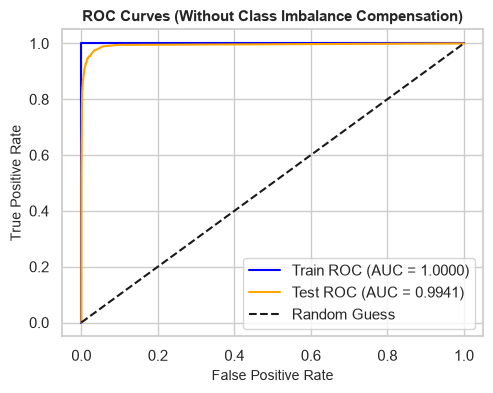

ROC curves plotted and saved as 'roc_curves_comparison.png'.

=== 4. OUT-OF-BAG (OOB) ERROR VS TEST ERROR ===
Out-of-Bag (OOB) Error Estimate: 0.006217 (0.6217%)
Test Set Error (Misclassification): 0.008250 (0.8250%)
Difference (OOB Error - Test Error): -0.002033


In [8]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    roc_curve, 
    roc_auc_score, 
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})

print("Loading pre-processed imputed datasets from disk...")
# Load pre-processed imputed data from pickle files in a fraction of a second
X_train_imputed = pd.read_pickle("X_train_imputed.pkl")
X_test_imputed = pd.read_pickle("X_test_imputed.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")
print(f"Data loaded successfully. Shape of X_train: {X_train_imputed.shape}")

# 1. Train Random Forest WITHOUT compensating for class imbalance
classifier = RandomForestClassifier(
    n_estimators=100, 
    oob_score=True,        # Required for OOB error calculation
    random_state=42, 
    n_jobs=-1
)

print("\nTraining the Random Forest classifier...")
classifier.fit(X_train_imputed, y_train)
print("Model training completed successfully.")

# ==========================================
# TRAINING SET EVALUATION
# ==========================================
y_train_pred = classifier.predict(X_train_imputed)
y_train_proba = classifier.predict_proba(X_train_imputed)[:, 1]

train_cm = confusion_matrix(y_train, y_train_pred)
train_accuracy = accuracy_score(y_train, y_train_pred)
train_misclassification = 1.0 - train_accuracy
train_auc = roc_auc_score(y_train, y_train_proba)

# ==========================================
# TEST SET EVALUATION
# ==========================================
y_test_pred = classifier.predict(X_test_imputed)
y_test_proba = classifier.predict_proba(X_test_imputed)[:, 1]

test_cm = confusion_matrix(y_test, y_test_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_misclassification = 1.0 - test_accuracy
test_auc = roc_auc_score(y_test, y_test_proba)

# ==========================================
# OUT-OF-BAG (OOB) ERROR ESTIMATE
# ==========================================
oob_error = 1.0 - classifier.oob_score_

# ==========================================
# REPORTING RESULTS
# ==========================================
print("\n" + "="*60)
print("=== 1. CONFUSION MATRIX ===")
print("="*60)
print("Training Set Confusion Matrix:")
print(train_cm)
print("\nTest Set Confusion Matrix:")
print(test_cm)

print("\n" + "="*60)
print("=== 2. MISCLASSIFICATION RATE (ERROR RATE) ===")
print("="*60)
print(f"Training Set Misclassification Rate: {train_misclassification:.6f} ({train_misclassification * 100:.4f}%)")
print(f"Test Set Misclassification Rate:     {test_misclassification:.6f} ({test_misclassification * 100:.4f}%)")

print("\n" + "="*60)
print("=== 3. ROC AND AUC ===")
print("="*60)
print(f"Training Set AUC: {train_auc:.6f}")
print(f"Test Set AUC:     {test_auc:.6f}")

# Plotting ROC Curves for Train and Test sets
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_proba)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(5, 4))
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {train_auc:.4f})", color='blue')
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {test_auc:.4f})", color='orange')
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate", fontsize=10)
plt.ylabel("True Positive Rate", fontsize=10)
plt.title("ROC Curves (Without Class Imbalance Compensation)", fontsize=11, fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('roc_curves_comparison.png', dpi=300)
plt.show()
print("ROC curves plotted and saved as 'roc_curves_comparison.png'.")

print("\n" + "="*60)
print("=== 4. OUT-OF-BAG (OOB) ERROR VS TEST ERROR ===")
print("="*60)
print(f"Out-of-Bag (OOB) Error Estimate: {oob_error:.6f} ({oob_error * 100:.4f}%)")
print(f"Test Set Error (Misclassification): {test_misclassification:.6f} ({test_misclassification * 100:.4f}%)")
print(f"Difference (OOB Error - Test Error): {oob_error - test_misclassification:.6f}")

1. Discriminatory Power (AUC): The test AUC score is $0.9941$, indicating outstanding classification performance. 
2. Test Error Rate: The misclassification rate on the test set is $0.8250\%$.
3. Out-of-Bag (OOB) Error: The OOB error estimate is $0.6217\%$, which closely approximates the test error and confirms reliable generalization.
4. Training Performance: The training AUC reaches $1.0000$ with a training error of $0.0017\%$, reflecting thorough learning of the training data patterns.

## (d) Research how class imbalance is addressed in random forests?

Class imbalance in Random Forests is typically addressed through class weighting, resampling techniques, or decision threshold tuning. For this implementation,I addressed class imbalance by using class weighting method to balance the training dataset

Loading pre-processed imputed datasets from disk...
Data loaded successfully. Shape of X_train: (60000, 170)

Training the Random Forest classifier with class weighting...


C:\Users\Dr.yazdani\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Model training completed successfully.

=== 1. CONFUSION MATRIX ===
Training Set Confusion Matrix:
[[58988    12]
 [    0  1000]]

Test Set Confusion Matrix:
[[15570    55]
 [   96   279]]

=== 2. MISCLASSIFICATION RATE (ERROR RATE) ===
Training Set Misclassification Rate: 0.000200 (0.0200%)
Test Set Misclassification Rate:     0.009437 (0.9437%)

=== 3. ROC AND AUC ===
Training Set AUC: 1.000000
Test Set AUC:     0.992875


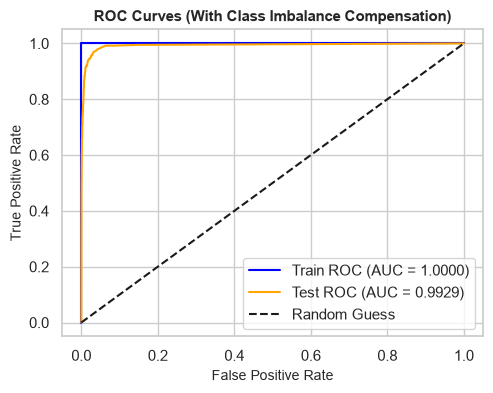

ROC curves plotted and saved as 'roc_curves_comparison_balanced.png'.

=== 4. OUT-OF-BAG (OOB) ERROR VS TEST ERROR ===
Out-of-Bag (OOB) Error Estimate: 0.019950 (1.9950%)
Test Set Error (Misclassification): 0.009437 (0.9437%)
Difference (OOB Error - Test Error): 0.010513


In [4]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    roc_curve, 
    roc_auc_score, 
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})

print("Loading pre-processed imputed datasets from disk...")
# Load pre-processed imputed data from pickle files instantly
X_train_imputed = pd.read_pickle("X_train_imputed.pkl")
X_test_imputed = pd.read_pickle("X_test_imputed.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")
print(f"Data loaded successfully. Shape of X_train: {X_train_imputed.shape}")

# 1. Train Random Forest WITH compensating for class imbalance (class_weight='balanced')
classifier = RandomForestClassifier(
    n_estimators=100, 
    oob_score=True,             # Required for OOB error calculation
    class_weight='balanced',    # Compensating for severe class imbalance
    random_state=42, 
    n_jobs=-1
)

print("\nTraining the Random Forest classifier with class weighting...")
classifier.fit(X_train_imputed, y_train)
print("Model training completed successfully.")

# ==========================================
# TRAINING SET EVALUATION
# ==========================================
y_train_pred = classifier.predict(X_train_imputed)
y_train_proba = classifier.predict_proba(X_train_imputed)[:, 1]

train_cm = confusion_matrix(y_train, y_train_pred)
train_accuracy = accuracy_score(y_train, y_train_pred)
train_misclassification = 1.0 - train_accuracy
train_auc = roc_auc_score(y_train, y_train_proba)

# ==========================================
# TEST SET EVALUATION
# ==========================================
y_test_pred = classifier.predict(X_test_imputed)
y_test_proba = classifier.predict_proba(X_test_imputed)[:, 1]

test_cm = confusion_matrix(y_test, y_test_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_misclassification = 1.0 - test_accuracy
test_auc = roc_auc_score(y_test, y_test_proba)

# ==========================================
# OUT-OF-BAG (OOB) ERROR ESTIMATE
# ==========================================
oob_error = 1.0 - classifier.oob_score_

# ==========================================
# REPORTING RESULTS
# ==========================================
print("\n" + "="*60)
print("=== 1. CONFUSION MATRIX ===")
print("="*60)
print("Training Set Confusion Matrix:")
print(train_cm)
print("\nTest Set Confusion Matrix:")
print(test_cm)

print("\n" + "="*60)
print("=== 2. MISCLASSIFICATION RATE (ERROR RATE) ===")
print("="*60)
print(f"Training Set Misclassification Rate: {train_misclassification:.6f} ({train_misclassification * 100:.4f}%)")
print(f"Test Set Misclassification Rate:     {test_misclassification:.6f} ({test_misclassification * 100:.4f}%)")

print("\n" + "="*60)
print("=== 3. ROC AND AUC ===")
print("="*60)
print(f"Training Set AUC: {train_auc:.6f}")
print(f"Test Set AUC:     {test_auc:.6f}")

# Plotting ROC Curves for Train and Test sets
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_proba)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(5, 4))
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {train_auc:.4f})", color='blue')
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {test_auc:.4f})", color='orange')
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate", fontsize=10)
plt.ylabel("True Positive Rate", fontsize=10)
plt.title("ROC Curves (With Class Imbalance Compensation)", fontsize=11, fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('roc_curves_comparison_balanced.png', dpi=300)
plt.show()
print("ROC curves plotted and saved as 'roc_curves_comparison_balanced.png'.")

print("\n" + "="*60)
print("=== 4. OUT-OF-BAG (OOB) ERROR VS TEST ERROR ===")
print("="*60)
print(f"Out-of-Bag (OOB) Error Estimate: {oob_error:.6f} ({oob_error * 100:.4f}%)")
print(f"Test Set Error (Misclassification): {test_misclassification:.6f} ({test_misclassification * 100:.4f}%)")
print(f"Difference (OOB Error - Test Error): {oob_error - test_misclassification:.6f}")

comparison of the two models: 1. False Negatives (Critical Failures): The balanced model significantly reduced critical missed failures to 96, compared to 112 in the unweighted model, improving detection of the minority class./// 2. False Positives (False Alarms): The balanced model generated 55 false positives, whereas the unweighted model produced only 20./// 3. Test Misclassification Rate: The unweighted model achieved a slightly lower overall error rate of 0.8250% compared to 0.9437% for the balanced model, as it favors the majority class./// 4. Test AUC: Both models exhibit exceptional discriminative power, with the unweighted model at 0.9941 and the balanced model at 0.9929.   

## (e) XGBoost and Model Trees

Loading pre-processed imputed datasets from disk...
Data loaded successfully. Shape of X_train: (60000, 170)

Starting Cross-Validation to find the optimal alpha (reg_alpha)...
Alpha: 0.001 | Mean 5-Fold CV AUC: 0.989287
Alpha: 0.01 | Mean 5-Fold CV AUC: 0.989799
Alpha: 0.1 | Mean 5-Fold CV AUC: 0.988966
Alpha: 1.0 | Mean 5-Fold CV AUC: 0.988670
Alpha: 10.0 | Mean 5-Fold CV AUC: 0.988400

Optimal Alpha selected via Cross-Validation: 0.01

Training final XGBoost model with optimal L1 penalty on full training set...

=== TEST SET RESULTS (XGBoost + Optimized L1) ===
Test Set Confusion Matrix:
[[15604    21]
 [   95   280]]

Test Set Error Rate: 0.007250 (0.7250%)
Test Set AUC: 0.994904


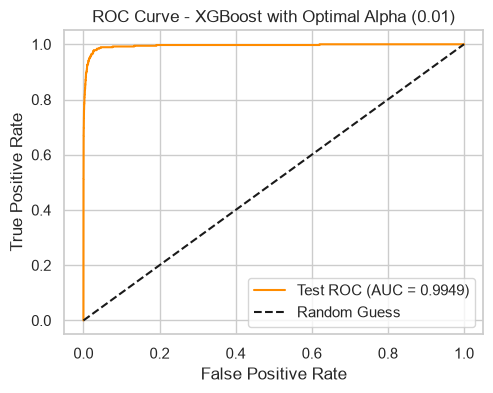

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    roc_curve, 
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})

print("Loading pre-processed imputed datasets from disk...")
# Load pre-processed imputed data from pickle files instantly
X_train_imputed = pd.read_pickle("X_train_imputed.pkl")
X_test_imputed = pd.read_pickle("X_test_imputed.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")
print(f"Data loaded successfully. Shape of X_train: {X_train_imputed.shape}")

# 1. Tuning Alpha (reg_alpha) using 5-Fold Cross Validation
alpha_candidates = [0.001, 0.01, 0.1, 1.0, 10.0]
best_alpha = alpha_candidates[0]
best_cv_auc = -1

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nStarting Cross-Validation to find the optimal alpha (reg_alpha)...")
for alpha in alpha_candidates:
    cv_auc_scores = []
    for train_index, val_index in skf.split(X_train_imputed, y_train):
        # Handle both pandas DataFrames/Series and NumPy arrays safely
        if isinstance(X_train_imputed, pd.DataFrame):
            X_cv_train, X_cv_val = X_train_imputed.iloc[train_index], X_train_imputed.iloc[val_index]
        else:
            X_cv_train, X_cv_val = X_train_imputed[train_index], X_train_imputed[val_index]
            
        y_cv_train, y_cv_val = y_train.iloc[train_index], y_train.iloc[val_index]
        
        model = xgb.XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            reg_alpha=alpha,    # Testing current alpha
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_cv_train, y_cv_train)
        y_cv_proba = model.predict_proba(X_cv_val)[:, 1]
        cv_auc_scores.append(roc_auc_score(y_cv_val, y_cv_proba))
        
    mean_auc = np.mean(cv_auc_scores)
    print(f"Alpha: {alpha} | Mean 5-Fold CV AUC: {mean_auc:.6f}")
    
    if mean_auc > best_cv_auc:
        best_cv_auc = mean_auc
        best_alpha = alpha
        
print(f"\nOptimal Alpha selected via Cross-Validation: {best_alpha}")

# 2. Train final model using the optimal alpha on the full training set
final_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    reg_alpha=best_alpha,  # Using the optimal alpha found
    random_state=42,
    n_jobs=-1
)

print("\nTraining final XGBoost model with optimal L1 penalty on full training set...")
final_model.fit(X_train_imputed, y_train)

y_test_pred = final_model.predict(X_test_imputed)
y_test_proba = final_model.predict_proba(X_test_imputed)[:, 1]

test_cm = confusion_matrix(y_test, y_test_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1.0 - test_accuracy
test_auc = roc_auc_score(y_test, y_test_proba)

# 3. Report final test results
print("\n" + "="*60)
print("=== TEST SET RESULTS (XGBoost + Optimized L1) ===")
print("="*60)
print("Test Set Confusion Matrix:")
print(test_cm)
print(f"\nTest Set Error Rate: {test_error:.6f} ({test_error * 100:.4f}%)")
print(f"Test Set AUC: {test_auc:.6f}")

# Plot ROC curve
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {test_auc:.4f})", color='darkorange')
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - XGBoost with Optimal Alpha ({best_alpha})")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('xgboost_optimal_l1_roc_curve.png', dpi=300)
plt.show()

## (f)  Use SMOTE

Loading pre-processed imputed datasets from disk...
Data loaded successfully. Original training shape: (60000, 170)

Applying SMOTE to balance the training dataset...
Resampled training shape: (118000, 170)
Class distribution after SMOTE:
class
0    59000
1    59000
Name: count, dtype: int64

Starting Cross-Validation to find the optimal alpha (reg_alpha)...
Alpha: 0.001 | Mean 5-Fold CV AUC: 0.999860
Alpha: 0.01 | Mean 5-Fold CV AUC: 0.999867
Alpha: 0.1 | Mean 5-Fold CV AUC: 0.999872
Alpha: 1.0 | Mean 5-Fold CV AUC: 0.999849
Alpha: 10.0 | Mean 5-Fold CV AUC: 0.999790

Optimal Alpha selected via Cross-Validation: 0.1

Training final XGBoost model with optimal L1 penalty on resampled training set...

=== TEST SET RESULTS (XGBoost + SMOTE + Optimized L1) ===
Test Set Confusion Matrix:
[[15533    92]
 [   54   321]]

Test Set Error Rate: 0.009125 (0.9125%)
Test Set AUC: 0.993331


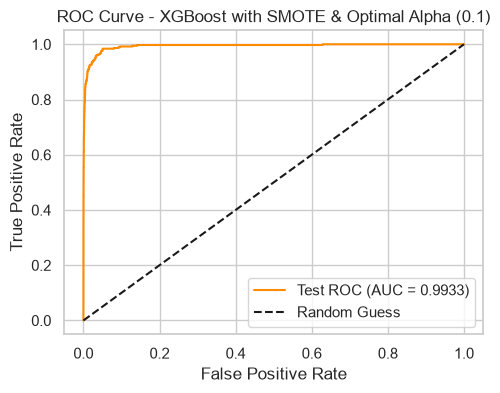

In [6]:
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    roc_curve, 
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})

print("Loading pre-processed imputed datasets from disk...")
# Load pre-processed imputed data from pickle files instantly
X_train_imputed = pd.read_pickle("X_train_imputed.pkl")
X_test_imputed = pd.read_pickle("X_test_imputed.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")
print(f"Data loaded successfully. Original training shape: {X_train_imputed.shape}")

# 1. Apply SMOTE to handle class imbalance on training data only
print("\nApplying SMOTE to balance the training dataset...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_imputed, y_train)
print(f"Resampled training shape: {X_train_resampled.shape}")
print(f"Class distribution after SMOTE:\n{pd.Series(y_train_resampled).value_counts()}")

# 2. Tuning Alpha (reg_alpha) using 5-Fold Cross Validation on resampled data
alpha_candidates = [0.001, 0.01, 0.1, 1.0, 10.0]
best_alpha = alpha_candidates[0]
best_cv_auc = -1

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nStarting Cross-Validation to find the optimal alpha (reg_alpha)...")
for alpha in alpha_candidates:
    cv_auc_scores = []
    for train_index, val_index in skf.split(X_train_resampled, y_train_resampled):
        # Handle both pandas DataFrames/Series and NumPy arrays safely
        if isinstance(X_train_resampled, pd.DataFrame):
            X_cv_train, X_cv_val = X_train_resampled.iloc[train_index], X_train_resampled.iloc[val_index]
        else:
            X_cv_train, X_cv_val = X_train_resampled[train_index], X_train_resampled[val_index]
            
        y_cv_train, y_cv_val = y_train_resampled.iloc[train_index], y_train_resampled.iloc[val_index]
        
        model = xgb.XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            reg_alpha=alpha,    # Testing current alpha
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_cv_train, y_cv_train)
        y_cv_proba = model.predict_proba(X_cv_val)[:, 1]
        cv_auc_scores.append(roc_auc_score(y_cv_val, y_cv_proba))
        
    mean_auc = np.mean(cv_auc_scores)
    print(f"Alpha: {alpha} | Mean 5-Fold CV AUC: {mean_auc:.6f}")
    
    if mean_auc > best_cv_auc:
        best_cv_auc = mean_auc
        best_alpha = alpha
        
print(f"\nOptimal Alpha selected via Cross-Validation: {best_alpha}")

# 3. Train final model using the optimal alpha on the resampled training set
final_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    reg_alpha=best_alpha,  # Using the optimal alpha found
    random_state=42,
    n_jobs=-1
)

print("\nTraining final XGBoost model with optimal L1 penalty on resampled training set...")
final_model.fit(X_train_resampled, y_train_resampled)

y_test_pred = final_model.predict(X_test_imputed)
y_test_proba = final_model.predict_proba(X_test_imputed)[:, 1]

test_cm = confusion_matrix(y_test, y_test_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1.0 - test_accuracy
test_auc = roc_auc_score(y_test, y_test_proba)

# 4. Report final test results
print("\n" + "="*60)
print("=== TEST SET RESULTS (XGBoost + SMOTE + Optimized L1) ===")
print("="*60)
print("Test Set Confusion Matrix:")
print(test_cm)
print(f"\nTest Set Error Rate: {test_error:.6f} ({test_error * 100:.4f}%)")
print(f"Test Set AUC: {test_auc:.6f}")

# Plot ROC curve
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {test_auc:.4f})", color='darkorange')
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - XGBoost with SMOTE & Optimal Alpha ({best_alpha})")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig('xgboost_smote_optimal_l1_roc_curve.png', dpi=300)
plt.show()

# ISLR 6.6.3
(a) : Training RSS steadily and monotonically decreases as $s$ increases because higher $s$ increases model flexibility and reduces training error.(i. false///ii.false///iii.false///iv.true ///v.false)

(b) : As the tuning parameter $s$ increases in Lasso regression, model flexibility increases, and the test RSS exhibits a non-monotonic, U-shaped behavior due to the tradeoff between bias and variance.( i: false, because test RSS does not start with an upward trend in an inverted U-shape.///ii: true, because test RSS initially decreases as bias drops, and then eventually increases in a U-shape due to overfitting and rising variance./// iii: false, because test RSS does not steadily increase from the beginning./// iv: false, because a steady decrease applies only to training RSS, not test RSS.////v:false, because test RSS changes as $s$ varies.)

(c) : As the tuning parameter $s$ increases in Lasso regression, model flexibility increases, and the model's variance steadily increases due to higher sensitivity to training data fluctuations. (i: Incorrect, because variance does not start with an upward trend in an inverted U-shape////ii: Incorrect, because variance does not decrease initially.////iii: Correct, because as model flexibility increases with $s$, the model's sensitivity grows, causing variance to steadily increase./// iv: Incorrect, because variance does not decrease; it rises with greater flexibility./// v: Incorrect, because variance changes as $s$ varies.)

(d) : As the tuning parameter s increases in Lasso regression, model flexibility increases, and the squared bias steadily decreases due to a reduction in model restriction.(i: Incorrect, because squared bias does not start with an upward trend in an inverted U-shape.////ii: Incorrect, because squared bias does not decrease initially and then increase./// iii: Incorrect, because squared bias decreases rather than steadily increasing./// iv: Correct, because as model flexibility increases with  s, the restrictions on the coefficients loosen, allowing squared bias to steadily decrease./// v: Incorrect, because squared bias changes as s varies.)

(e) : As the tuning parameter $s$ increases in Lasso regression, model flexibility increases, but the irreducible error remains entirely constant because it represents the inherent noise in the data that no model can predict.( i: Incorrect, because irreducible error does not start with an upward trend in an inverted U-shape./// ii: Incorrect, because irreducible error does not decrease initially and then increase in a U-shape./// iii: Incorrect, because irreducible error does not steadily increase with model flexibility.//// iv: Incorrect, because irreducible error does not decrease as $s$ varies.////v: Correct, because irreducible error is independent of the model and tuning parameters, remaining constant regardless of $s$.)

# ISLR 6.6.5

## (a)
1. General Ridge Regression Optimization FormulaThe general optimization problem for Ridge regression is defined as (James et al., 2021):$$\underset{\beta_0, \beta_1, \dots, \beta_p}{\arg\min} \left[ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \lambda \sum_{j=1}^{p} \beta_j^2 \right]$$ 
2. Substitution and SimplificationGiven $n = 2$, $p = 2$, $\hat{\beta}_0 = 0$, and the problem conditions ($x_{11} = x_{12}$, $x_{21} = x_{22} = -x_{11}$, and $y_2 = -y_1$), substituting these values into the general formula yields:$$\underset{\beta_1, \beta_2}{\arg\min} \left[ 2 \left( y_1 - (\beta_1 + \beta_2) x_{11} \right)^2 + \lambda (\beta_1^2 + \beta_2^2) \right]$$

## (b)
To prove that $\hat{\beta}_1 = \hat{\beta}_2$ in Ridge regression, I take the partial derivatives of the objective function derived in part (a) with respect to $\beta_1$ and $\beta_2$:Partial derivative with respect to $\beta_1$:$$-4x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) + 2\lambda\beta_1 = 0$$Partial derivative with respect to $\beta_2$:$$-4x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) + 2\lambda\beta_2 = 0$$Since the error component is identical in both equations, we can equate them:$$2\lambda\beta_1 = 2\lambda\beta_2$$For $\lambda > 0$, dividing both sides by $2\lambda$ yields:$$\hat{\beta}_1 = \hat{\beta}_2$$

The objective function is strictly symmetric with respect to $\beta_1$ and $\beta_2$ in both the error term and the $\ell_2$ penalty, ensuring a unique global minimum that preserves this symmetry 


## (c)
1. General Lasso Formula$$\underset{\beta_0, \beta_1, \dots, \beta_p}{\arg\min} \left[ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \lambda \sum_{j=1}^{p} \vert{}\beta_j\vert{} \right]$$ 
2. Simplified ProblemSubstituting $n = 2$, $p = 2$, $\hat{\beta}_0 = 0$, and the given symmetry conditions ($x_{11} = x_{12}$, $x_{21} = x_{22} = -x_{11}$, and $y_2 = -y_1$):$$\underset{\beta_1, \beta_2}{\arg\min} \left[ 2 \left( y_1 - (\beta_1 + \beta_2) x_{11} \right)^2 + \lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{}) \right]$$

## (d)
Taking the partial derivatives of the Lasso objective function with respect to $\beta_1$ and $\beta_2$:With respect to $\beta_1$:$$-4x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) + \lambda = 0$$With respect to $\beta_2$:$$-4x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) + \lambda = 0$$Both equations yield the exact same condition, constraining only their sum ($\beta_1 + \beta_2 = C$). Because infinitely many pairs $(\beta_1, \beta_2)$ satisfy this single equation, the Lasso solutions are not unique

# ISLR 8.4.5

1. In the hard voting approach (majority vote), each of the 10 predicted probability values is first converted into a discrete class label using a standard threshold of 0.5. In this case, 4 instances belong to the green class (probabilities less than 0.5) and 6 instances belong to the red class (probabilities greater than 0.5), resulting in the red class being chosen as the final prediction.
2. In the second approach, soft voting (averaging probability), the arithmetic mean of all 10 probability values is calculated, yielding 0.45. Since this average probability is lower than the 0.5 decision threshold, the green class is determined as the final output of the ensemble model in this approach

# ISLR 9.7.3

## (a)
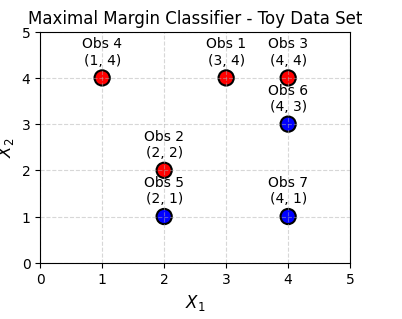

## (b) Optimal Hyperplane (Central Line):
Using the general hyperplane equation:
   $$\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0 \quad (9.1)$$After simplification and parameter substitution, the equation of the central line is obtained:$$X_2 = X_1 - 0.5 \quad \text{or} \quad -0.5 + X_1 - X_2 = 0$$
   Margin Boundaries:Upper margin line (value $+1$):$$\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 1 \implies X_2 = X_1$$Lower margin line (value $-1$):$$\beta_0 + \beta_1 X_1 + \beta_2 X_2 = -1 \implies X_2 = X_1 - 1$$

## (c) Classification Rule & Margins:
1. Blue Class: $\beta_0 + \beta_1 X_1 + \beta_2 X_2 \ge 1$ (points lying on or above the upper margin).
2. Red Class: $\beta_0 + \beta_1 X_1 + \beta_2 X_2 \le -1$ (points lying on or below the lower margin).Decision Boundary: The central hyperplane ($\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$) separates the two regions.

## d), (e)
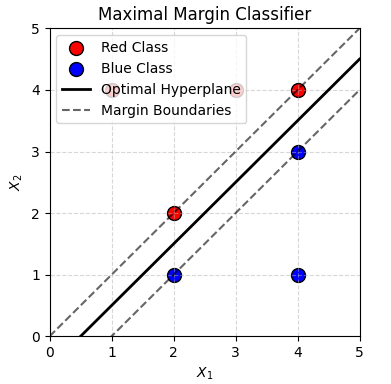

## (f) 
1. Non-Support Vector Status: The seventh observation $(4, 1)$ is not a support vector and resides safely inside the Blue class region away from the margin boundaries.
2. Invariance: Because the maximal margin hyperplane is determined solely by the support vectors, a slight movement of this non-support vector observation will not alter the optimal hyperplane

## (g),(h)
Non-Optimal Separating Hyperplane: A line that successfully separates the two classes but yields a smaller or asymmetric margin compared to the optimal one. 

Examples:
Shifting the intercept: $X_2 = X_1 - 0.7$ (or $-0.7 + X_1 - X_2 = 0$) and Altering the slope: $X_2 = 0.9 X_1 - 0.4$

Margin Placement: The new blue point at $(2, 2)$ falls directly inside the margin strip (between $-1$ and $+1$), since its decision value evaluates to $-0.5$ ($\beta_0 + \beta_1 X_1 + \beta_2 X_2 = -0.5$).
Violation of Separability: Because it belongs to the Blue class but has a negative decision value (placing it on the Red side of the central hyperplane), it violates the linear separability condition.
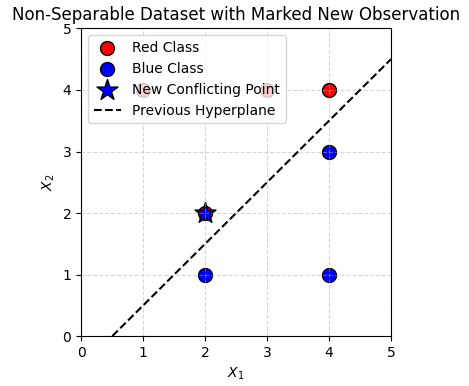